1- IMPORTS

In [1]:
import numpy as np
import keras
import tensorflow as tf
from tensorflow.keras import layers
import cv2 as cv
import os
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import log_loss, roc_curve, auc, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import Pipeline
import pandas as pd
from sklearn.impute import SimpleImputer
import time

2- DATASET PATHS

In [2]:
train_image_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/train/images"
train_txt_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/train/labels"

valid_image_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/valid/images"
valid_txt_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/valid/labels"

test_image_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/test/images"
test_txt_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/test/labels"

3- BUILDING THE MODEL

In [3]:
base_model = keras.applications.ResNet50(
    weights='imagenet',  # Pretrained on ImageNet
    input_shape=(150, 150, 3),
    include_top=False  # Remove classification head
)
base_model.trainable = False  # Freeze weights

# Build Feature Extraction Model
inputs = keras.Input(shape=(150, 150, 3))
x = keras.layers.Rescaling(scale=1 / 97.5, offset=-1)(inputs)
x = base_model(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
feature_extractor = keras.Model(inputs, x)
feature_extractor.summary()  # Print model architecture



Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 150, 150, 3)]     0         
                                                                 
 rescaling (Rescaling)       (None, 150, 150, 3)       0         
                                                                 
 resnet50 (Functional)       (None, 5, 5, 2048)        23587712  
                                                                 
 global_average_pooling2d (  (None, 2048)              0         
 GlobalAveragePooling2D)                                         
                                                                 
Total params: 23587712 (89.98 MB)
Trainable params: 0 (0.00 Byte)
Non-trainable params: 23587712 (89.98 MB)
_________________________________________________________________


4- LOAD IMAGES LABELS

In [4]:
def load_labels_for_images(label_dir, image_filenames):
    """Loads labels for specific image filenames from text files in a directory."""
    labels = []
    for filename in image_filenames:  # Process sorted filenames
        label_file_path = os.path.join(label_dir, filename.replace(".jpg", ".txt"))
        if os.path.exists(label_file_path):
            with open(label_file_path, 'r') as file:
                label_line = file.read().strip().split()
                class_label = int(label_line[0])  # Assuming first value is label
                labels.append(class_label)
    return labels

5- EXTRACT FEATURES FROM THE DATASET

In [5]:
def extract_features(folder, target_size=(150, 150)):
    """Extracts CNN features for all images in the given folder."""
    features = []
    
    filenames = sorted([f for f in os.listdir(folder) if f.endswith(".jpg")]) 
    
    for filename in filenames:
        img_path = os.path.join(folder, filename)
        img = cv.imread(img_path)
        img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
        img = cv.resize(img, target_size)
        img = np.expand_dims(img, axis=0)  # Add batch dimension
        
        feature_vector = feature_extractor.predict(img)  # Extract CNN features
        features.append(feature_vector.flatten())  # Flatten
        
    return np.array(features), filenames  # Return features and filenames

6- LOAD LABELS AND EXTRACT FEATURES

In [6]:
# Load filenames (sorted for consistency)
train_filenames = sorted([f for f in os.listdir(train_image_path) if f.endswith(".jpg")])
valid_filenames = sorted([f for f in os.listdir(valid_image_path) if f.endswith(".jpg")])
test_filenames = sorted([f for f in os.listdir(test_image_path) if f.endswith(".jpg")])

# Load labels for each dataset
train_labels = load_labels_for_images(train_txt_path, train_filenames)
valid_labels = load_labels_for_images(valid_txt_path, valid_filenames)
test_labels = load_labels_for_images(test_txt_path, test_filenames)

# Extract features
start_time_train = time.time()
X_train, _ = extract_features(train_image_path)
y_train = train_labels
end_time_train = time.time()
train_time_min = (end_time_train - start_time_train)/ 60

start_time_valid = time.time()
X_valid, _ = extract_features(valid_image_path)
y_valid = valid_labels
end_time_valid = time.time()
valid_time_min = (end_time_valid - start_time_valid)/ 60

start_time_test = time.time()
X_test, _ = extract_features(test_image_path)
y_test = test_labels
end_time_test = time.time()
test_time_min = (end_time_test - start_time_test)/ 60

total_cnn_features = (
    X_train.shape[0] * X_train.shape[1] +
    X_valid.shape[0] * X_valid.shape[1] +
    X_test.shape[0] * X_test.shape[1]
)

# Ensure label count matches feature count
assert len(X_train) == len(train_labels), "Mismatch in train features and labels!"
assert len(X_valid) == len(valid_labels), "Mismatch in validation features and labels!"
assert len(X_test) == len(test_labels), "Mismatch in test features and labels!"


1/1 [==============================] - 0s 191ms/step


7- BUILD LOGREG CLASSIFIER

In [ ]:
start_time_logreg = time.time()
# step 1: Standardize features
scaler = StandardScaler()

# step 2: Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# step 3: Transform validation and test data
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

# step 4: Hyperparameter grid for Logistic Regression
param_grid_lr = {'logisticregression__C': [0.01, 0.1, 0.5, 1, 10, 50, 100]}

# Train logistic regression model
pipe_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),  # Ensure scaling is included in the pipeline
    ('logisticregression', LogisticRegression(max_iter=1000, random_state=42))
])

# step 5: KFold cross-validation definition
kf_regular = KFold(n_splits=5, shuffle=True, random_state=42) #Creates a K-Fold splitter that divides your training data (X_train_scaled) into 5 different splits.
oof_preds_train = np.zeros((X_train_scaled.shape[0],)) #Creates an empty array the size of the training set to store out-of-fold (OOF) predictions.

y_train = np.array(y_train) #Ensures y_train is a NumPy array so that it can be indexed by train_idx and val_idx.
# loop for each fold
for train_idx, val_idx in kf_regular.split(X_train_scaled):
    '''
    Splits X_train_scaled into 5 different train-validation combinations.
    train_idx → indices of the training data in this fold.
    val_idx → indices of the validation data in this fold.
    '''
    X_tr, X_val = X_train_scaled[train_idx], X_train_scaled[val_idx] #Splits the data into training and validation sets for this fold.
    y_tr, y_val = y_train[train_idx], y_train[val_idx] #Splits the labels into training and validation sets for this fold.
    # step 6: Perform GridSearchCV with Logistic Regression and KFold
    logreg_kf = GridSearchCV(pipe_lr, param_grid_lr, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
    logreg_kf.fit(X_tr, y_tr)
    best_lr_model = logreg_kf.best_estimator_
    oof_preds_train[val_idx] = best_lr_model.predict_proba(X_val)[:, 1]
    '''
    This way, when all 5 folds are done, oof_preds_train contains predictions for every training sample, 
    but made only using models that didn't train on that sample — avoiding data leakage.
    '''
    '''
    ✅ Summary:
    You're using nested cross-validation:
    Outer loop = 5-fold split
    Inner loop = GridSearchCV with 5-fold.
    After each fold, you're saving the predicted probabilities on validation data.
    This is a robust way to evaluate and tune models without overfitting on the training data.
    '''
end_time_logreg = time.time()

best_lr_model.fit(X_train_scaled, y_train)
# Step 7: Make predictions
logreg_train_pred = best_lr_model.predict_proba(X_train_scaled)[:, 1]
logreg_valid_pred = best_lr_model.predict_proba(X_valid_scaled)[:, 1]
logreg_test_pred = best_lr_model.predict_proba(X_test_scaled)[:, 1]
train_prediction = best_lr_model.predict(X_train_scaled)
valid_prediction = best_lr_model.predict(X_valid_scaled)
test_prediction = best_lr_model.predict(X_test_scaled)

# Step 8: Get evaluation metrics
train_score_logreg = logreg_kf.score(X_train_scaled, y_train)
valid_score_logreg = logreg_kf.score(X_valid_scaled, y_valid)
test_score_logreg = logreg_kf.score(X_test_scaled, y_test)
class_report = classification_report(y_test, test_prediction, target_names=["Car", "Ship"]) 
cm = confusion_matrix(y_test, test_prediction)
train_size = X_train_scaled.shape
valid_size = X_valid_scaled.shape
test_size = X_test_scaled.shape
cross_entropy_loss = log_loss(y_test, logreg_test_pred)
logreg_time = end_time_logreg - start_time_logreg
logreg_time_min = logreg_time/60
class_names = ['Car', 'Ship']
# prediction_labels = [class_names[pred] for pred in test_prediction]

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 7 candidates, totalling 35 fits


8- COMBINE ORIGINAL FEATURES WITH LOGREG OUTPUTS

In [8]:
X_train_combined = np.hstack((X_train_scaled, oof_preds_train.reshape(-1, 1)))# the output of the for loop used here
X_valid_combined = np.hstack((X_valid_scaled, logreg_valid_pred.reshape(-1, 1)))
X_test_combined = np.hstack((X_test_scaled, logreg_test_pred.reshape(-1, 1)))
X_train_combined_df = pd.DataFrame(X_train_combined)
print("NaNs in train:", np.isnan(X_train_combined).sum())
print("Infs in train:", np.isinf(X_train_combined).sum())

NaNs in train: 0
Infs in train: 0


9- BUILD XGBOOST CLASSIFIER

In [9]:
start_time_xgboost = time.time()

# Step 1: Hyperparameter grid for XGBoost (with pipeline)
param_grid_xgb = {
    'xgbclassifier__n_estimators': [10, 100, 200], #The number of trees (or boosting rounds) in the model.
    'xgbclassifier__max_depth': [3, 5], #Maximum depth of each tree (branches).
    'xgbclassifier__learning_rate': [0.01, 0.1, 0.2], #Controls how much each tree contributes to the final prediction.
    'xgbclassifier__subsample': [0.8, 1.0], #Fraction of the training data randomly sampled for growing each tree.1.0 means use all the data. 0.8 means use only 80% for each tree — helps prevent overfitting.
    'xgbclassifier__colsample_bytree': [0.8, 1.0] #Fraction of features (columns) randomly sampled for each tree.Like subsample, this helps reduce overfitting and improve generalization.
}

# Step 2: XGBoost pipeline
pipe_xgb = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
    ('xgbclassifier', XGBClassifier(
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=42
        ))
])

# Step 3: KFold cross-validation definition
kf_regular = KFold(n_splits=5, shuffle=True, random_state=42)

# Step 4: GridSearchCV with KFold
grid_xgb_kf_regular = GridSearchCV(pipe_xgb, param_grid_xgb, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
grid_xgb_kf_regular.fit(X_train_combined, y_train)
best_params = grid_xgb_kf_regular.best_params_

# Step 5: Use best params from grid to initialize a final model
xgb_model = XGBClassifier(    
    n_estimators=best_params['xgbclassifier__n_estimators'],
    max_depth=best_params['xgbclassifier__max_depth'],
    learning_rate=best_params['xgbclassifier__learning_rate'],
    subsample=best_params['xgbclassifier__subsample'],
    colsample_bytree=best_params['xgbclassifier__colsample_bytree'],
    eval_metric='logloss',
    random_state=42,
    )

# Step 6: Train on full combined training set
xgb_model.fit(
    X_train_combined, y_train,
    eval_set=[(X_valid_combined, y_valid)],  # Use validation set
    verbose=False
    )
end_time_xgboost = time.time()
xgboost_time = end_time_xgboost - start_time_xgboost
xgboost_time_min = xgboost_time/60

# Step 7: Make predictions
xgb_predictions = xgb_model.predict(X_test_combined)
xgb_probabilities = xgb_model.predict_proba(X_test_combined)[:, 1]

# Step 8: Get evaluation metrics
train_size_XGBoost = X_train_combined.shape
valid_size_XGBoost = X_valid_combined.shape
test_size_XGBoost = X_test_combined.shape
class_report_XGBoost = classification_report(y_test, xgb_predictions, target_names=["Car", "Ship"]) 
cm_XGBoost = confusion_matrix(y_test, xgb_predictions)
cross_entropy_loss_XGBoost = log_loss(y_test, xgb_probabilities)
train_score_XGBoost = xgb_model.score(X_train_combined, y_train)
valid_score_XGBoost = xgb_model.score(X_valid_combined, y_valid)
test_score_XGBoost = xgb_model.score(X_test_combined, y_test)

Fitting 5 folds for each of 72 candidates, totalling 360 fits


C:\Users\omare\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [16:20:35] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


9- PRINTING THE OUTPUTS

In [10]:
'''Number of features'''
print(f"[Train] Extracted CNN features from {X_train.shape[0]} images")
print(f"[Train] Each image has a feature vector of length {X_train.shape[1]}")
print(f"[Train] Total CNN features shape: {X_train.shape}")
print(f"[Valid] Extracted CNN features from {X_valid.shape[0]} images")
print(f"[Valid] Each image has a feature vector of length {X_valid.shape[1]}")
print(f"[Valid] Total CNN features shape: {X_valid.shape}")
print(f"[Test] Extracted CNN features from {X_test.shape[0]} images")
print(f"[Test] Each image has a feature vector of length {X_test.shape[1]}")
print(f"[Test] Total CNN features shape: {X_test.shape}")
print(f"Total number of CNN feature values (flattened): {total_cnn_features}")

'''feature extraction time'''
print(f"[Train] Feature extraction train took {train_time_min:.2f} minutes")
print(f"[Valid] Feature extraction valid took {valid_time_min:.2f} minutes")
print(f"[Test] Feature extraction test took {test_time_min:.2f} minutes")

'''logreg'''
print("Best parameters with Regular KFold for Logistic Regression:", logreg_kf.best_params_)
print("Best score for with Regular KFold Logistic Regression:", logreg_kf.best_score_*100,"%")
print(f"Train size for Logistic Regression: {train_size}\n")
print(f"Valid  size for Logistic Regression: {valid_size}\n")
print(f"Test size for Logistic Regression: {test_size}\n")
print(f"Class report for Logistic Regression:\n{class_report}\n")
print(f"Train Predictions for Logistic Regression: {train_prediction}\n")
print(f"Test Predictions for Logistic Regression: {test_prediction}\n")
print(f"Train Score for Logistic Regression: {train_score_logreg * 100:.2f}%\n")
print(f"Valid Score for Logistic Regression: {valid_score_logreg * 100:.2f}%\n")
print(f"Test Score for Logistic Regression: {test_score_logreg * 100:.2f}%\n")
print(f"Confusion matrix for Logistic Regression:\n {cm}\n")
print(f"Cross Entropy Loss for Logistic Regression: {cross_entropy_loss:.4f}\n")
print(f"Logreg time: {logreg_time_min} minute")

'''XGBoost'''
print("Best parameters with Regular KFold for XGBoost:", grid_xgb_kf_regular.best_params_)
print("Best score with Regular KFold for XGBoost:", grid_xgb_kf_regular.best_score_*100,"%")
print(f"Train XGBoost size: {train_size_XGBoost}")
print(f"Valid XGBoost size: {valid_size_XGBoost}")
print(f"Test XGBoost size: {test_size_XGBoost}")
print(f"Classification Report for XGBoost:\n{class_report_XGBoost}")
print(f"XGBoost Train Accuracy: {train_score_XGBoost * 100:.2f}%")
print(f"XGBoost Valid Accuracy: {valid_score_XGBoost * 100:.2f}%")
print(f"XGBoost Test Accuracy: {test_score_XGBoost * 100:.2f}%")
print(f"Confusion Matrix:\n{cm_XGBoost}")
print(f"Cross Entropy Loss for XGBoost: {cross_entropy_loss_XGBoost:.4f}")
print(f"XGBoost time: {xgboost_time_min} minute")

'''total time'''
total_time = train_time_min + test_time_min + logreg_time_min + xgboost_time_min + valid_time_min
print(f"Total time taken: {total_time} minute")

[Train] Extracted CNN features from 10000 images
[Train] Each image has a feature vector of length 2048
[Train] Total CNN features shape: (10000, 2048)
[Valid] Extracted CNN features from 2307 images
[Valid] Each image has a feature vector of length 2048
[Valid] Total CNN features shape: (2307, 2048)
[Test] Extracted CNN features from 1999 images
[Test] Each image has a feature vector of length 2048
[Test] Total CNN features shape: (1999, 2048)
Total number of CNN feature values (flattened): 29298688
[Train] Feature extraction train took 67.88 minutes
[Valid] Feature extraction valid took 10.77 minutes
[Test] Feature extraction test took 9.97 minutes
Best parameters with Regular KFold for Logistic Regression: {'logisticregression__C': 0.1}
Best score for with Regular KFold Logistic Regression: 97.03750000000001 %
Train size for Logistic Regression: (10000, 2048)

Valid  size for Logistic Regression: (2307, 2048)

Test size for Logistic Regression: (1999, 2048)

Class report for Logisti

10- PLOTTING THE OUTPUTS

10.1- CONFUSION MATRIX   

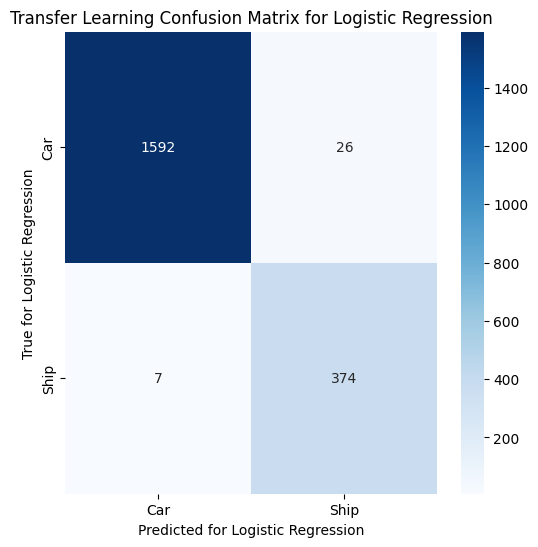

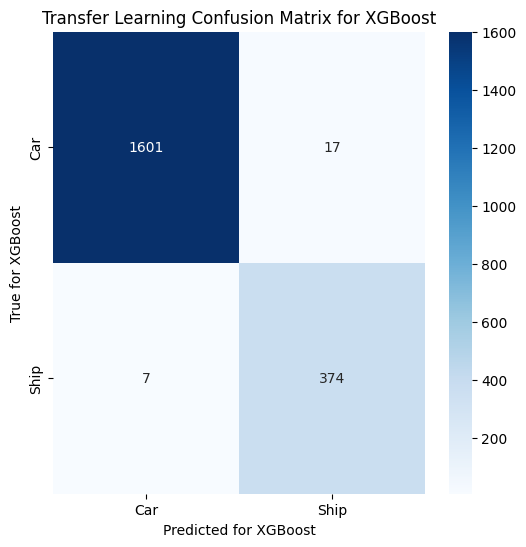

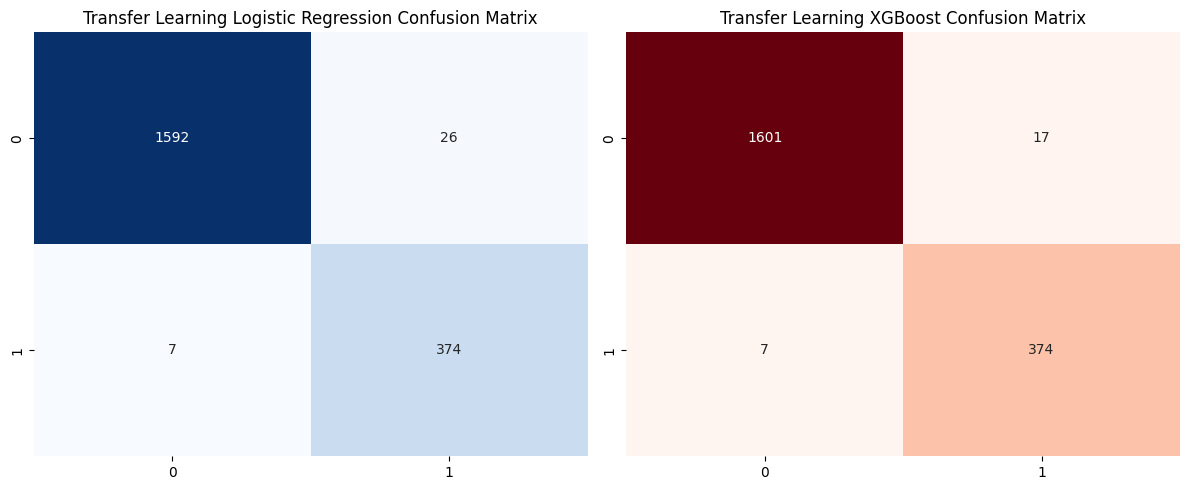

In [16]:
plt.figure(figsize=(6,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Car", "Ship"], yticklabels=["Car", "Ship"])
plt.title("Transfer Learning Confusion Matrix for Logistic Regression")
plt.xlabel("Predicted for Logistic Regression")
plt.ylabel("True for Logistic Regression")
plt.show()

plt.figure(figsize=(6,6))
sns.heatmap(cm_XGBoost, annot=True, fmt='d', cmap='Blues', xticklabels=["Car", "Ship"], yticklabels=["Car", "Ship"])
plt.title("Transfer Learning Confusion Matrix for XGBoost")
plt.xlabel("Predicted for XGBoost")
plt.ylabel("True for XGBoost")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])  
ax[0].set_title('Transfer Learning Logistic Regression Confusion Matrix')  
sns.heatmap(cm_XGBoost, annot=True, fmt='d', cmap='Reds', cbar=False, ax=ax[1])
ax[1].set_title('Transfer Learning XGBoost Confusion Matrix')
plt.tight_layout()   
plt.show()

10.2- ROC CURVE

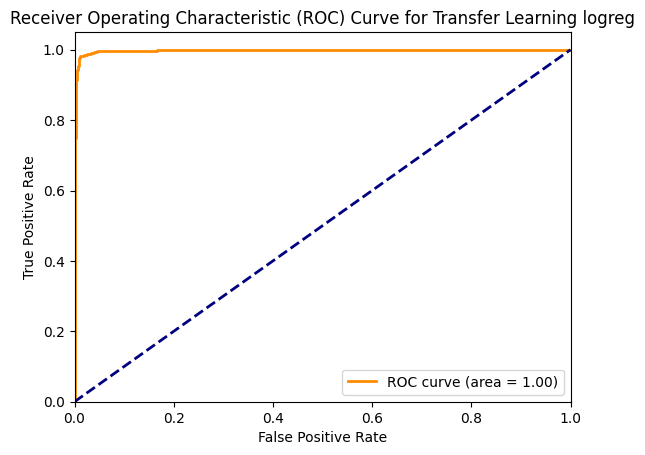

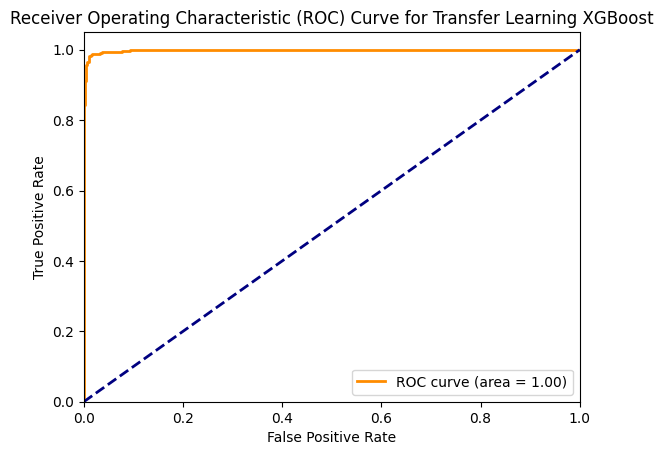

In [17]:
fpr, tpr, thresholds = roc_curve(y_test, logreg_test_pred)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for Transfer Learning logreg')
plt.legend(loc="lower right")
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, xgb_probabilities)    
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for Transfer Learning XGBoost')
plt.legend(loc="lower right")
plt.show()


10.3- EXECUTION TIME

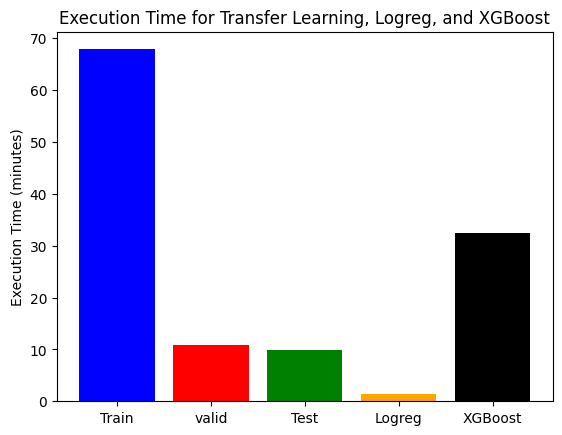

In [18]:
plt.bar(['Train', 'valid', 'Test', 'Logreg', 'XGBoost'], [train_time_min, valid_time_min, test_time_min, logreg_time_min, xgboost_time_min], color=['blue', 'red', 'green', 'orange', 'black'])
plt.ylabel('Execution Time (minutes)')
plt.title('Execution Time for Transfer Learning, Logreg, and XGBoost')
plt.show()

10.4- CROSS ENTROPY LOSS

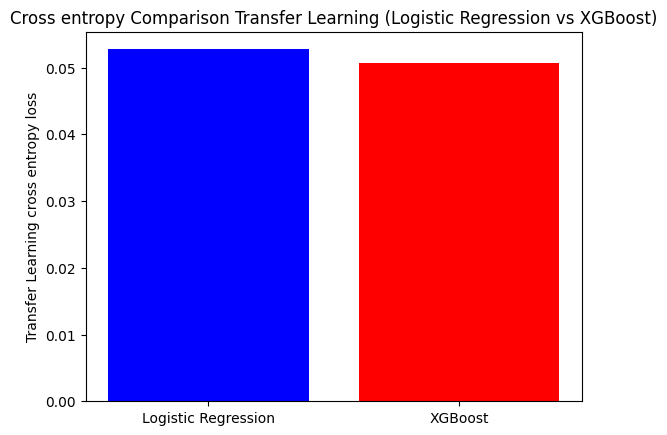

In [19]:
plt.bar(['Logistic Regression', 'XGBoost'], [cross_entropy_loss, cross_entropy_loss_XGBoost], color=['blue', 'red'])
plt.ylabel('Transfer Learning cross entropy loss')
plt.title('Cross entropy Comparison Transfer Learning (Logistic Regression vs XGBoost)')
plt.show()

10.5- TRAINING VS TESTING ACCURACY

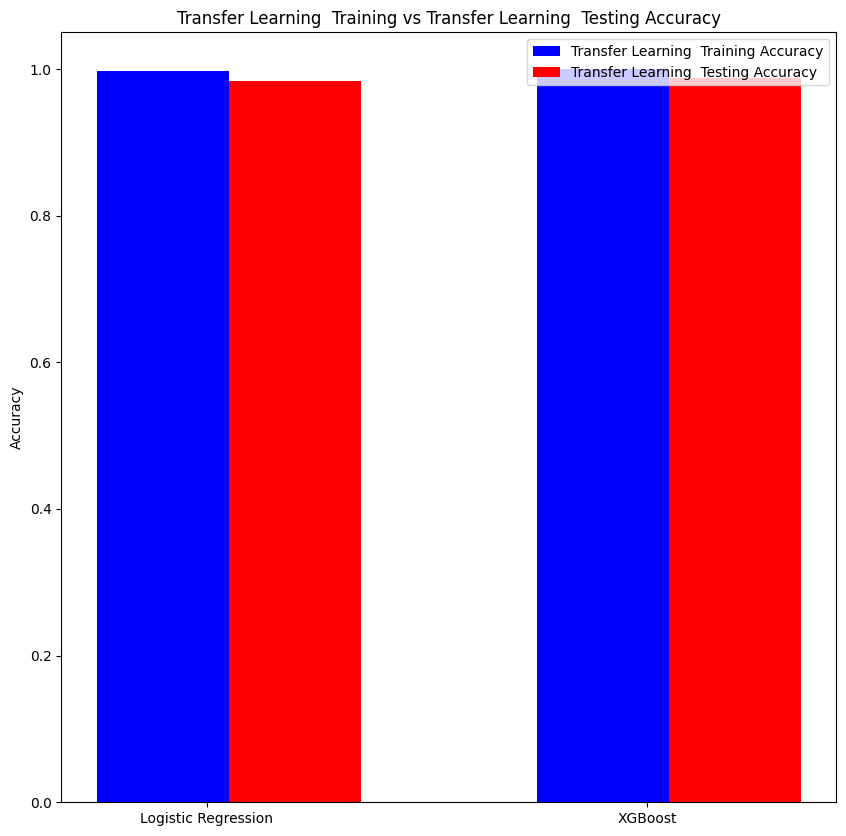

In [20]:
labels = ['Logistic Regression', 'XGBoost']
train_accuracies = [train_score_logreg, train_score_XGBoost]
test_accuracies = [test_score_logreg, test_score_XGBoost]
x = range(len(labels))
width = 0.3
fig, ax4 = plt.subplots(figsize=(10, 10))
ax4.bar(x, train_accuracies, width=width, label='Transfer Learning  Training Accuracy', color='blue')
ax4.bar([p + width for p in x], test_accuracies, width=width, label='Transfer Learning  Testing Accuracy', color='red')
ax4.set_xticks([p + width / 3 for p in x])
ax4.set_xticklabels(labels)
ax4.set_ylabel('Accuracy')
ax4.set_title('Transfer Learning  Training vs Transfer Learning  Testing Accuracy')
ax4.legend()
plt.show()